This is a copy of the implementation done in 10, however this time we will use a learning rate of 1e-4 instead of 5e-4 (5x decrease). The best checkpoint found in experiment 09 will be used, as the experiment in 10 did not yield a better checkpoint.

# Install Torchgeo

In [18]:
!uv pip install torchgeo

Using Python 3.13.15 environment at: /usr
Checked 1 package in 216ms


# Imports

In [19]:
import numpy as np
import gc

import torch
import torch.nn.functional as F
from torchgeo.models import ResNet18_Weights, resnet18
from torchgeo.trainers import SemanticSegmentationTask
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2

import lightning.pytorch as pl
from lightning.pytorch.loggers import TensorBoardLogger
from lightning.pytorch.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
)

import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from pathlib import Path

# Load Google Drive for dataset

In [20]:
from google.colab import drive
drive.mount('/content/drive')
base_dir = "/content/drive/MyDrive/informal_settlement_segmentation"
data_dir = f"{base_dir}/data/deep_learning"
checkpoints_dir = f"{base_dir}/checkpoints/11"
logs_dir = f"{base_dir}/logs/11"
old_best_model_dir = f"{base_dir}/checkpoints/09/best.ckpt"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Setup Pytorch training and validation Datasets and Dataloaders with online augmentation functionality

In [35]:
def augment(image, mask):
    import random

    # flip horizontally with 50% chance
    if random.random() < 0.5:
        image = torch.flip(image, dims=[-1])
        mask = torch.flip(mask, dims=[-1])

    # flip vertically with 50% chance
    if random.random() < 0.5:
        image = torch.flip(image, dims=[-2])
        mask = torch.flip(mask, dims=[-2])

    # rotate 0, 90, 180, or 270 degree rotation each with 25% chance
    k = random.randint(0, 3)

    image = torch.rot90(image, k=k, dims=(-2, -1))
    mask = torch.rot90(mask, k=k, dims=(-2, -1))

    return image, mask

class TorchDataset(Dataset):
    def __init__(self, patches, apply_augmentation):
        self.patches = patches
        self.apply_augmentation = apply_augmentation

    def __len__(self): return len(self.patches)
    def __getitem__(self, idx):
        patch = torch.from_numpy(self.patches[idx])

        if self.apply_augmentation:
            image = patch[:-1]
            mask = patch[-1:]
            image, mask = augment(image, mask)
            patch = torch.cat([image, mask], dim=0)

        return patch

train_dataset = TorchDataset(np.load(data_dir + "/train_patches.npy"), apply_augmentation = True)
val_dataset = TorchDataset(np.load(data_dir + "/val_patches.npy"), apply_augmentation = False)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    pin_memory=True,
    num_workers=2,
    persistent_workers=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    pin_memory=True,
    num_workers=2,
    persistent_workers=True,
)

# Load and inspect Torchgeo's resnet18 model pretrained on Sentinel-2 imagery

In [36]:
weights = ResNet18_Weights.SENTINEL2_ALL_MOCO
print('Weight metadata:')
for key, value in weights.meta.items(): print(f' {key}: {value}')

Weight metadata:
 dataset: SSL4EO-S12
 in_chans: 13
 model: resnet18
 publication: https://arxiv.org/abs/2211.07044
 repo: https://github.com/zhu-xlab/SSL4EO-S12
 ssl_method: moco
 bands: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8a', 'B9', 'B10', 'B11', 'B12']


# Override segmentation task to add batch upscaling functionality

In [37]:
class CustomSegmentationTask(SemanticSegmentationTask):
    def on_after_batch_transfer(self, batch, dataloader_idx=0):

        batch = F.interpolate(batch, size=(224, 224), mode="nearest")

        images = batch[:, :-1]
        masks  = batch[:, -1]

        return {"image": images, "mask": masks}

# Stage 1 training

# Load 09's best model, unfreeze encoder and reduce learning rate to 1e-4 (compared to 5e-4, used before).

In [38]:
task = CustomSegmentationTask(
    model="unet",
    backbone="resnet18",
    weights=weights,
    in_channels=13,
    task="binary",
    loss="jaccard",
    lr=1e-4,
    freeze_backbone=False,
)

checkpoint = torch.load(old_best_model_dir, map_location="cpu")
task.load_state_dict(checkpoint["state_dict"])

print(task.model)

Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(13, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, trac

# Check parameter distribution

In [39]:
encoder_params = sum(p.numel() for p in task.model.encoder.parameters())
decoder_params = sum(p.numel() for p in task.model.decoder.parameters())
head_params = sum(p.numel() for p in task.model.segmentation_head.parameters())

total_params = encoder_params + decoder_params + head_params

print(f"Encoder:     {encoder_params:,}")
print(f"Decoder:     {decoder_params:,}")
print(f"Head:        {head_params:,}")
print(f"Total:       {total_params:,}")

Encoder:     11,207,872
Decoder:     3,151,552
Head:        145
Total:       14,359,569


# Add checkpointing and early stopping functionality

In [40]:
phase2_best = ModelCheckpoint(
    dirpath=checkpoints_dir,
    filename="best",
    monitor="val_loss",
    mode="min",
    save_top_k=1,
    save_last=True,
)

phase2_periodic = ModelCheckpoint(
    dirpath=checkpoints_dir,
    filename="epoch-{epoch:03d}",
    every_n_epochs=5,
    save_top_k=-1,
)

phase2_early_stop = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=10,
    verbose=True,
)

# Create trainer and logger using Pytorch Lightning

In [41]:
logger_stage2 = TensorBoardLogger(
    save_dir=logs_dir,
    name="results",
)

trainer_stage2 = pl.Trainer(
    accelerator="gpu",
    devices=1,
    precision="16-mixed",
    max_epochs=100,
    logger=logger_stage2,
    callbacks=[
        phase2_best,
        phase2_periodic,
        phase2_early_stop,
    ],

    log_every_n_steps=1,
)

INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [42]:
trainer_stage2.fit(
    task,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader,
)

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model         │ Unet             │ 14.4 M │ train │     0 │
│ 1 │ criterion     │ JaccardLoss      │      0 │ train │     0 │
│ 2 │ train_metrics │ MetricCollection │      0 │ train │     0 │
│ 3 │ val_metrics   │ MetricCollection │      0 │ train │     0 │
│ 4 │ test_metrics  │ MetricCollection │      0 │ train │     0 │
└───┴───────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 14.4 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 14.4 M                                                                                               
Total estimated model params size (MB): 57.438                                                                     
Modules in train mode: 174                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO: Metric val_loss improved. New best score: 0.628
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved. New best score: 0.628
INFO: Metric val_loss improved by 0.079 >= min_delta = 0.0. New best score: 0.549
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved by 0.079 >= min_delta = 0.0. New best score: 0.549
INFO: Metric val_loss improved by 0.007 >= min_delta = 0.0. New best score: 0.542
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved by 0.007 >= min_delta = 0.0. New best score: 0.542
INFO: Metric val_loss improved by 0.028 >= min_delta = 0.0. New best score: 0.514
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved by 0.028 >= min_delta = 0.0. New best score: 0.514
INFO: Metric val_loss improved by 0.001 >= min_delta = 0.0. New best score: 0.513
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved by 0.001 >= min_delta = 0.0. New best score: 0.513
INFO: Metric val_loss impr

In [43]:
event_file = next(p for p in Path(logger_stage2.log_dir).glob("events.out.tfevents.*"))

ea = EventAccumulator(str(event_file))
ea.Reload()

for metric in ["train_loss", "val_loss",]:
    events = ea.Scalars(metric)

    print(
        metric,
        "points:", len(events),
        "first step:", events[0].step,
        "last step:", events[-1].step,
    )

train_loss points: 3564 first step: 0 last step: 3563
val_loss points: 36 first step: 98 last step: 3563


In [44]:
train_losses = [x.value for x in ea.Scalars("train_loss")]
val_losses = [x.value for x in ea.Scalars("val_loss")]

In [45]:
train_losses_np = np.array(train_losses)

num_epochs = len(val_losses)
steps_per_epoch = len(train_losses_np) // num_epochs

# Reshape: rows = epochs, columns = batches within each epoch
epoch_losses = train_losses_np.reshape(num_epochs, steps_per_epoch)

# Average batch losses within each epoch
train_loss_per_epoch = epoch_losses.mean(axis=1)
train_loss_per_epoch.shape

(36,)

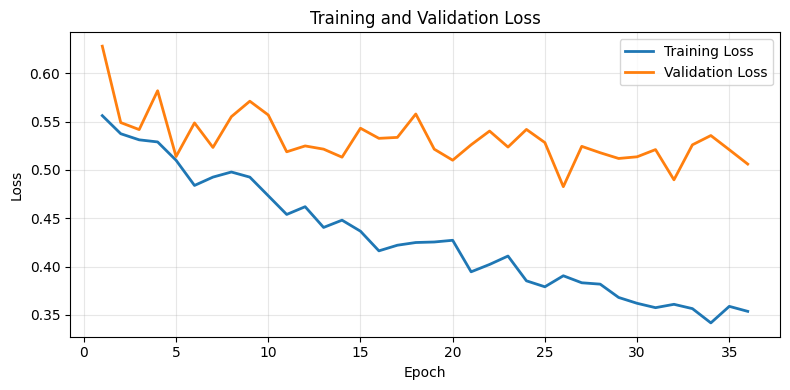

In [46]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 4))

plt.plot(epochs, train_loss_per_epoch, label="Training Loss", linewidth=2)
plt.plot(epochs, val_losses, label="Validation Loss", linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [47]:
train_jaccard_scores = [x.value for x in ea.Scalars("train_AverageJaccardIndex")]
val_jaccard_scores = [x.value for x in ea.Scalars("val_AverageJaccardIndex")]

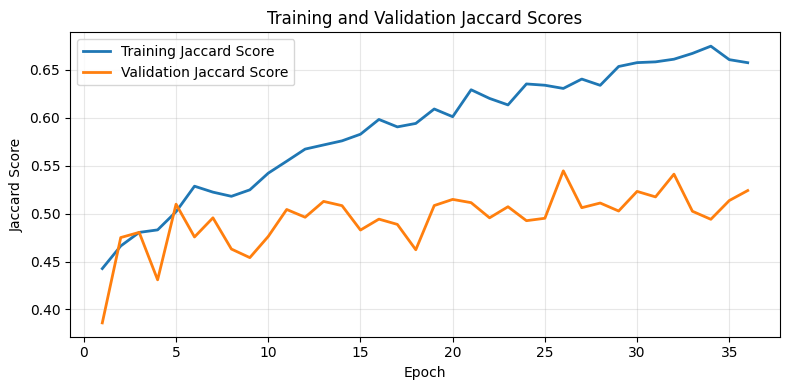

In [48]:
plt.figure(figsize=(8, 4))

plt.plot(epochs, train_jaccard_scores, label="Training Jaccard Score", linewidth=2)
plt.plot(epochs, val_jaccard_scores, label="Validation Jaccard Score", linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Jaccard Score")
plt.title("Training and Validation Jaccard Scores")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Analysis

The unfrozen encoder significantly improved model accuracy. The best validation loss obtained is 0.483 (compared to 0.522 in 09). Jaccard score also increased as seen from the graphs.

On the other hand, the loss graphs indicate that overfitting is occurring again, as the model's validation loss plateaus quickly, while training loss keeps decreasing gradually untill the early stopping mechanism stops training.
This overfitting happens despite online augmentation still being applied during training.

My proposed solution is to apply weight decay to the best checkpoint of this current model.